# 🟠 Tarefa 1

*   Disciplina: Física com Python 1 (2026.2) — CBPF
*   Autor: Luiz Guilherme Ataliba dos Reis
*   Obs: Código desenvolvido para fins de avaliação acadêmica. Disponibilizado publicamente sob a Licença MIT para consulta educacional.

In [154]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy import stats
from numba import njit
import plotly.graph_objects as go
from plotly.colors import sample_colorscale
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation

sns.set_theme('notebook')
sns.set_style("darkgrid")

## 🔵 Problema Escolhido
Para essa atividade vamos utilizar o standard map, dado pelas relações

$$
    p_{n+1} = p_n + K\sin(x_n),\\
    x_{n+1} = x_n + p_{n+1},
$$
onde limitamos os valores de forma que $p, x \in [0, 2\pi]$

### 🔷 Definição do Mapa Standard

In [155]:
TAU = 2 * np.pi

@njit
def standard_map(p0, x0, N, K=1):
    ps = np.empty(N+1)
    xs = np.empty(N+1)

    ps[0] = p0 % TAU
    xs[0] = x0 % TAU
    
    for i in range(N):
        ps[i+1] = (ps[i] + K * np.sin(xs[i])) % TAU
        xs[i+1] = (xs[i] + ps[i+1]) % TAU

    return xs, ps

X, P = standard_map(0, 1, 100, 1)

Text(0.02, 0.5, 'Momento angular, $p$')

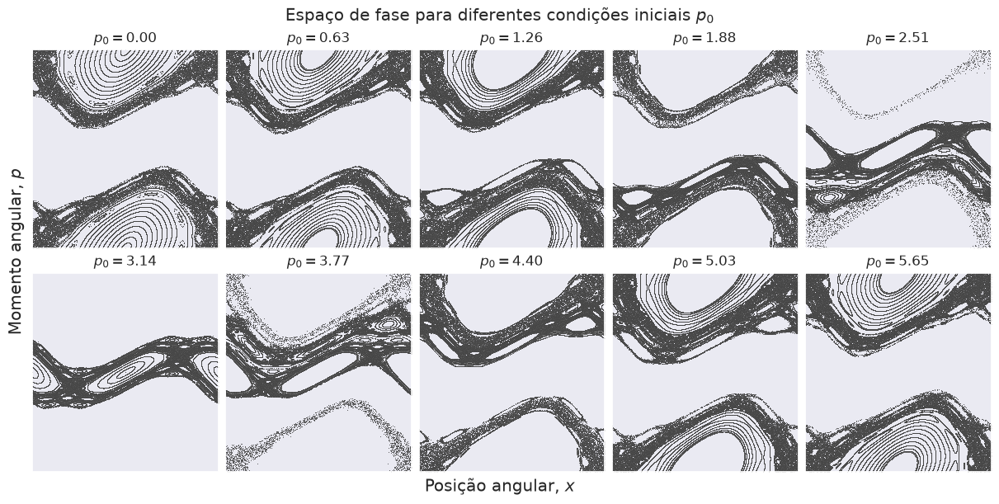

In [156]:
fig, axs = plt.subplots(2, 5, constrained_layout=True, figsize=(12, 6), sharex=True, sharey=True)
axs = axs.flatten()

for ax, p0 in zip(axs, np.linspace(0, TAU, 10, endpoint=False)):
    for x0 in np.linspace(0, TAU, 40, endpoint=False):
        X, P = standard_map(p0, x0, 4000)
        sns.scatterplot(x=X, y=P, s=0.5, color="black", ax=ax)
        
        ax.set_xlim(0, TAU)
        ax.set_ylim(0, TAU)
        ax.set_title(fr"$p_0 = {p0:.2f}$")
        ax.set_xticks([])
        ax.set_yticks([])
    
fig.suptitle("Espaço de fase para diferentes condições iniciais $p_0$")
fig.supxlabel("Posição angular, $x$")
fig.supylabel("Momento angular, $p$")


### 🔷 Cálculo do Expoente de Lyapunov
Para alguns gráficos, vamos visualizar a distribuição do exponente de lyapunov para esse sistema. Para isso, primeiramente construímos a matriz Jacobiana do sistema:
$$
    J = \begin{pmatrix}1 + K\cos(x_n) & 1 \\ K\cos(x_n) & 1\end{pmatrix},
$$
partindo de um vetor perturbação unitário $v_0 = (1,0)$ sua evolução é dada por:
$$
    w_{n+1} = J_n v_n,
$$
e em cada iteração, calculamos o fator $s_n = ||w_{n+1}||$ e normalizamos o vetor
$$
    v_{n+1} = \frac{w_{n+1}}{s_n}.
$$
Com isso, podemos calcular o expoente de lyapunov, após N iterações:
$$
    \boxed{\lambda_N = \frac{1}{N}\sum_{n=0}^{N-1}\ln(s_n)}
$$

In [157]:
@njit
def lyapunov_exponent(p0, x0, N, K=1):
    xs, ps = standard_map(p0, x0, N, K)
    

    # Initial tangent vector
    v = np.array([1.0, 0.0])
    sum_log = 0.0

    # Iterating over the whole simulation
    for n in range(N):
        # Jacobian for the standard-map
        J = np.array([
            [1 + K * np.cos(xs[n]), 1],
            [K * np.cos(xs[n]), 1]
        ])

        # Matrix multiplication
        w = J @ v

        s = np.linalg.norm(w)
        sum_log += np.log(s)

        # Restore v to unit length
        v = w/s

    return sum_log / N

def lyapunov_2d(p0_values, x0_values, N, K):
    exponents = []
    for p0 in p0_values:
        for x0 in x0_values:
            lamb = lyapunov_exponent(p0=p0, x0=x0, N=N, K=K)

            exponents.append(lamb)

    return exponents

## 🔶 Q1

Aplique o **ridge-plot** (gráfico de cordilheira) para visualizar algum resultado da sua grande área de pesquisa.

**ridge-plot**:
*  https://seaborn.pydata.org/examples/kde_ridgeplot
*  https://python-graph-gallery.com/ridgeline-graph-seaborn/


In [158]:
# Generating the data

K_values = [0.2, 0.7, 1.0, 2.0, 4.0, 7.0]
N=1000
n_points=50

x0s = np.linspace(0, TAU, n_points)
p0s = np.linspace(0, TAU, n_points)

data = {}
for K in K_values:
    data[f"K={K}"] = lyapunov_2d(p0s, x0s, N, K)

data = pd.DataFrame(data)

In [159]:
# Using plotly for easier notation

fig = go.Figure()
colors = sample_colorscale(
    "Magma",
    samplepoints=np.linspace(0.15, 0.9, len(K_values)),
)

for K, color in zip(K_values, colors):
    fig.add_trace(
        go.Violin(
            x=data[f"K={K}"],
            name=f"K = {K}",
            side="positive",
            width=3,
            points=False,
            fillcolor=color,
            line_color=color,
            showlegend=False,
        )
    )

fig.update_layout(
    width=1000,
    height=500,
    violinmode="overlay",
    title="Distribuição do expoente de Lyapunov no mapa padrão",
    xaxis_title="Expoente de Lyapunov, λₙ",
    yaxis_title="Parâmetro K",
    showlegend=False,
)

fig.show()

## 🔶 Q2

Aplique o **ternary-plot** (gráfico ternário) para visualizar algum resultado da sua grande área de pesquisa.

**ternary-plot**:
*  https://plotly.com/python/ternary-plots/
*  https://www.geeksforgeeks.org/python/ternary-plots-in-plotly/


### 🔷 Teoria
Como estamos calculando o expoente de Lyapunov em tempo finito (até $N$ iterações) estamos sob efeitos de convergência. Então, para o gráfico ternário vamos calcular o expoente de Lyapunov para $N$ e $2N$ e a partir desses dois valores definir os seguintes cenários:

1. **Caótico**: $\lambda_N$ e $\lambda_{2N}$ são **maiores que zero** e eles convergem para valores próximos
2. **Regular**: $\lambda_N$ e $\lambda_{2N}$ são **aproximadamente zero** e eles convergem para valores próximos
3. **Intermediário**: Os demais casos, em especial quando $\lambda_N$ e $\lambda_{2N}$ ainda não convergiram para o mesmo valor (precisa-se de mais execuções)


Esse cáculo é realizado para diferentes valores de $K$. Para quantificar maiores/aproximadamente zero introduzimos uma tolerância *epsilon_zero* e para quantificar a se $\lambda_N$ e $\lambda_{2N}$ convergiram introduzimos *epsilon_convergence*

In [160]:
def phase_space_fractions(
    p0_values,
    x0_values,
    N,
    K,
    epsilon_zero,
    epsilon_convergence,
):
    regular = 0
    intermediate = 0
    chaotic = 0

    for p0 in p0_values:
        for x0 in x0_values:
            lambda_N = lyapunov_exponent(p0, x0, N, K)
            lambda_2N = lyapunov_exponent(p0, x0, 2 * N, K)

            if abs(lambda_N) < epsilon_zero and abs(lambda_2N) < epsilon_zero:
                regular += 1
            elif (
                lambda_2N > epsilon_zero
                and abs(lambda_2N - lambda_N) < epsilon_convergence
            ):
                chaotic += 1
            else:
                intermediate += 1

    total = regular + intermediate + chaotic

    return regular / total, intermediate / total, chaotic / total


In [161]:
# Generating the data

K_values = np.concatenate(
    (
        np.linspace(0.0, 1.0, 12),
        np.linspace(1.5, 5.0, 12),
        np.linspace(6.0, 15.0, 12),
    )
)
N = 1000
n_points = 50
epsilon_zero = 0.02
epsilon_convergence = 0.02

x0s = np.linspace(0, TAU, n_points)
p0s = np.linspace(0, TAU, n_points)

regular_fractions = []
intermediate_fractions = []
chaotic_fractions = []

for K in K_values:
    regular, intermediate, chaotic = phase_space_fractions(
        p0s, x0s, N, K, epsilon_zero, epsilon_convergence
    )

    regular_fractions.append(regular)
    intermediate_fractions.append(intermediate)
    chaotic_fractions.append(chaotic)


In [162]:
fig = go.Figure(
    go.Scatterternary(
        a=chaotic_fractions,
        b=intermediate_fractions,
        c=regular_fractions,
        mode="markers",
        marker=dict(
            size=12,
            color=K_values,
            colorscale="Magma",
            showscale=True,
            colorbar=dict(title="Parâmetro K"),
        ),
        showlegend=False,
    )
)

fig.update_layout(
    title="Composição do espaço de fase do mapa padrão",
    ternary=dict(
        sum=1,
        aaxis_title="Caótico",
        baxis_title="Intermediário / não resolvido",
        caxis_title="Regular",
    ),
)

fig.show()


## 🔶 Q3

Faça um gráfico com **inset** para visualizar algum resultado da sua grande área de pesquisa.

Exemplo:
https://scipython.com/blog/inset-plots-in-matplotlib/

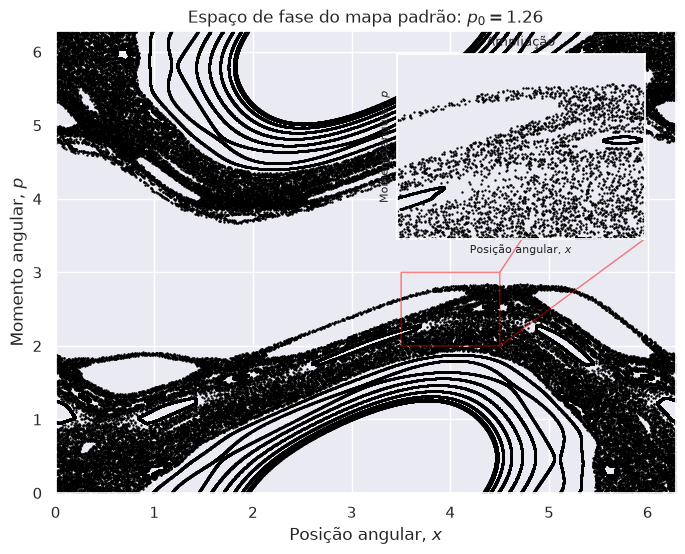

In [163]:
# Generating the data
p0 = 2 * TAU / 10
x0s = np.linspace(0, TAU, 40, endpoint=False)

# Plotting
x_min, x_max = 3.5, 4.5
p_min, p_max = 2.0, 3.0

fig, ax = plt.subplots(figsize=(8, 6))
ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])

for x0 in x0s:
    X, P = standard_map(p0, x0, 4000)
    ax.scatter(X, P, s=0.5, color="black")
    ax_inset.scatter(X, P, s=0.5, color="black")

ax.set(
    xlim=(0, TAU),
    ylim=(0, TAU),
    title=fr"Espaço de fase do mapa padrão: $p_0 = {p0:.2f}$",
)
ax.set_xlabel("Posição angular, $x$")
ax.set_ylabel("Momento angular, $p$")

ax_inset.set(xlim=(x_min, x_max), ylim=(p_min, p_max))
ax_inset.set_title("Ampliação", fontsize=9)
ax_inset.set_xlabel("Posição angular, $x$", fontsize=8)
ax_inset.set_ylabel("Momento angular, $p$", fontsize=8)
ax_inset.set_xticks([])
ax_inset.set_yticks([])
ax.indicate_inset_zoom(ax_inset, edgecolor="red")

plt.show()


## 🔶 Q4

Faça um gráfico com **animação** para visualizar dinamicamente algum resultado da sua grande área de pesquisa.


Exemplos: https://python-graph-gallery.com/animation/

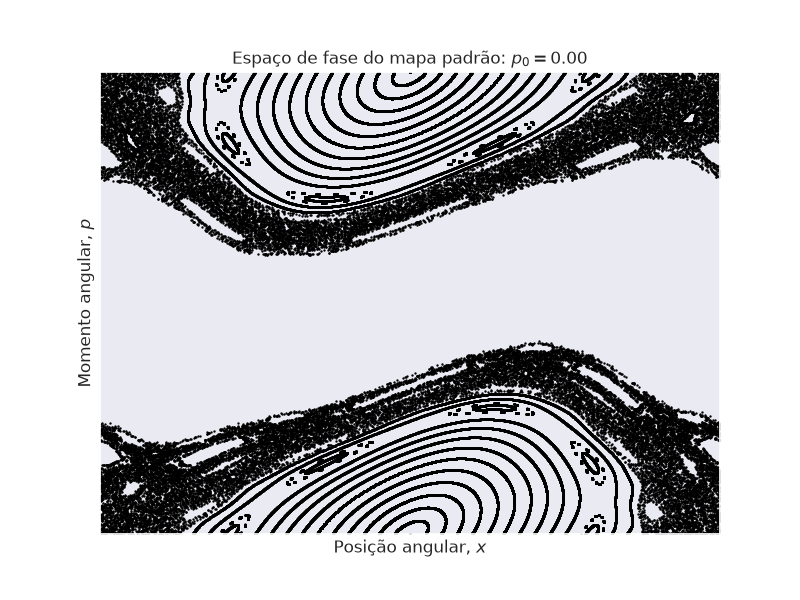

In [164]:
# Generating the data
x0s = np.linspace(0, TAU, 40, endpoint=False)
p0s = np.linspace(0, TAU, 120, endpoint=False)


# Plotting
fig, ax = plt.subplots(figsize=(8, 6))

def update(frame):
    ax.clear()
    p0 = p0s[frame]

    for x0 in x0s:
        X, P = standard_map(p0, x0, 4000)
        ax.scatter(X, P, s=0.5, color="black")

    ax.set(
        xlim=(0, TAU),
        ylim=(0, TAU),
        title=fr"Espaço de fase do mapa padrão: $p_0 = {p0:.2f}$",
    )
    ax.set_xlabel("Posição angular, $x$")
    ax.set_ylabel("Momento angular, $p$")
    ax.set_xticks([])
    ax.set_yticks([])

ani = FuncAnimation(fig, update, frames=len(p0s), interval=100)
gif_path = "standard_map_animation.gif"
ani.save(gif_path, writer="pillow", fps=10)

plt.close(fig)
display(Image(filename=gif_path))


## 🔶 Q5
Acesse a documentação do [scipy-stats](https://docs.scipy.org/doc/scipy/reference/stats.html) em seguida:

* Escolha 6 distribuições de [variáveis continuas](https://docs.scipy.org/doc/scipy/reference/stats.html#continuous-distributions)  que permitam discutir graficamente a **variância**, **skewness** e **kurtosis** de modo representativo. **Organize os paineis em grid 2x3 usando  [plt.subplots(nrows=2, ncols=3, figsize=(15, 8))](https://www.geeksforgeeks.org/data-visualization/how-to-generate-subplots-with-pythons-matplotlib/)**. Coloque no *título* de cada painel o valor da variância, skewness e kurtosis.


In [174]:
# Generating the data

distributions = [
    ("Normal", stats.norm()),
    ("Uniforme", stats.uniform()),
    ("Laplace", stats.laplace()),
    ("Exponencial", stats.expon()),
    ("Lognormal", stats.lognorm(s=0.5)),
    ("Pareto (α = 8)", stats.pareto(b=8)),
]

distribution_data = {}
for name, distribution in distributions:
    x_min, x_max = distribution.ppf([0.001, 0.999])
    x = np.linspace(x_min, x_max, 500)
    variance, skewness, kurtosis = distribution.stats(moments="vsk")

    distribution_data[name] = {
        "var": variance,
        "skew": skewness,
        "kurt": kurtosis + 3,
        "pdf": distribution.pdf(x),
        "X": x
    }

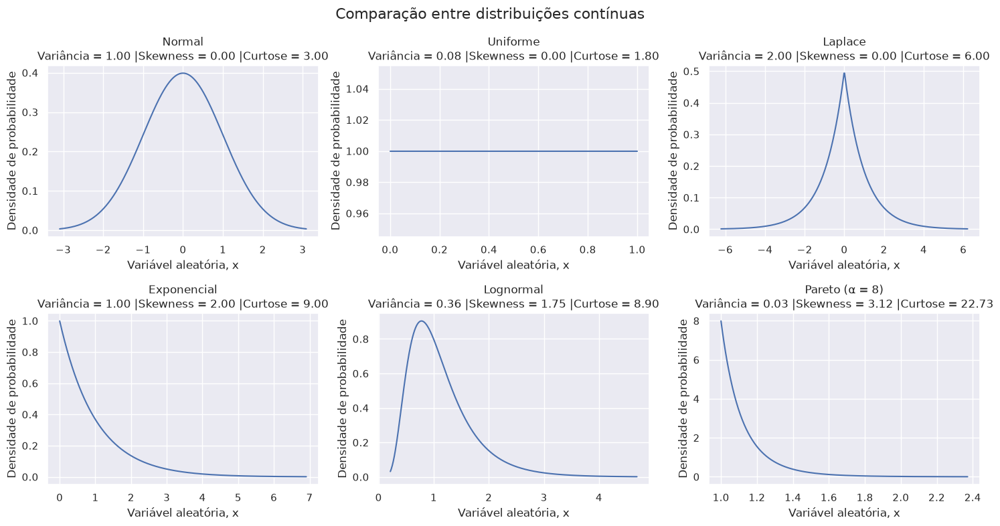

In [175]:
# Plotting

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))

for ax, (name, dist_stats) in zip(axs.flatten(), distribution_data.items()):
    sns.lineplot(x=dist_stats["X"], y=dist_stats["pdf"], ax=ax)

    ax.set_title(
        f"{name}\nVariância = {dist_stats["var"]:.2f} |"
        f"Skewness = {dist_stats["skew"]:.2f} |"
        f"Curtose = {dist_stats["kurt"]:.2f}"
    )
    ax.set_xlabel("Variável aleatória, x")
    ax.set_ylabel("Densidade de probabilidade")

fig.suptitle("Comparação entre distribuições contínuas", fontsize=16)
fig.tight_layout()

## 🔶 Q6
Acesse a documentação do [scipy-stats](https://docs.scipy.org/doc/scipy/reference/stats.html) em seguida:

* Escolha 6 distribuições de [variáveis discretas](https://docs.scipy.org/doc/scipy/reference/stats.html#discrete-distributions) que permitam discutir graficamente a **variância**, **skewness** e **kurtosis** de modo representativo. **Organize os paineis em grid 2x3 usando  [plt.subplots(nrows=2, ncols=3, figsize=(15, 8))](https://www.geeksforgeeks.org/data-visualization/how-to-generate-subplots-with-pythons-matplotlib/)**. Coloque no *título* de cada painel o valor da variância, skewness e kurtosis.




In [176]:
# Generating the data

discrete_distributions = [
    ("Bernoulli", stats.bernoulli(p=0.2)),
    ("Binomial", stats.binom(n=10, p=0.5)),
    ("Uniforme discreta", stats.randint(low=0, high=10)),
    ("Poisson", stats.poisson(mu=4)),
    ("Geométrica", stats.geom(p=0.3)),
    ("Binomial negativa", stats.nbinom(n=5, p=0.5)),
]

discrete_distribution_data = {}

for name, distribution in discrete_distributions:
    x_min, x_max = distribution.ppf([0.001, 0.999]).astype(int)
    x = np.arange(x_min, x_max + 1)
    variance, skewness, kurtosis = distribution.stats(moments="vsk")

    discrete_distribution_data[name] = {
        "x": x,
        "pmf": distribution.pmf(x),
        "var": variance,
        "skew": skewness,
        "kurt": kurtosis + 3,
    }


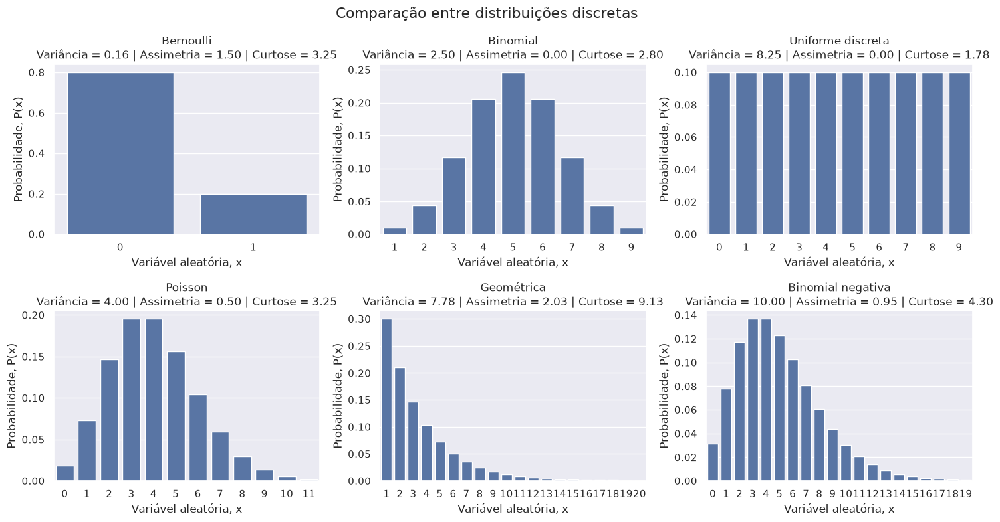

In [177]:
# Plotting

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))

for ax, (name, dist_stats) in zip(axs.flatten(), discrete_distribution_data.items()):
    sns.barplot(x=dist_stats["x"], y=dist_stats["pmf"], ax=ax)

    ax.set_title(
        f"{name}\n"
        f"Variância = {dist_stats['var']:.2f} | "
        f"Assimetria = {dist_stats['skew']:.2f} | "
        f"Curtose = {dist_stats['kurt']:.2f}"
    )
    ax.set_xlabel("Variável aleatória, x")
    ax.set_ylabel("Probabilidade, P(x)")

fig.suptitle("Comparação entre distribuições discretas", fontsize=16)
fig.tight_layout()